# Shrinkage covariance estimation (LedoitWolf vs OAS vs max-likelihood): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/covariance/plot_covariance_estimation.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/covariance/plot_covariance_estimation.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** 20 training and 20 test samples of 40 colored Gaussian features (`np.random.seed(42)`).
The negative test log-likelihood of `ShrunkCovariance(shrinkage=s).fit(X_train).score(X_test)` over 30
log-spaced shrinkages; `empirical_covariance` + `log_likelihood` for the true precision; `GridSearchCV`
over `shrinkage` (default 5-fold `KFold`, the estimator's own `score`); `LedoitWolf` and `OAS` shrinkage
coefficients and test scores.

**Beyond the gallery:** learned `covariance_`, `precision_`, `location_`, `shrinkage_`; the functional forms
`ledoit_wolf`, `ledoit_wolf_shrinkage`, `oas`, `shrunk_covariance`; `error_norm` (Frobenius/spectral, scaled or not);
`mahalanobis`; `store_precision=False` with `get_precision()`; keyword `set_params` + refit; `clone` of a fitted
estimator (unfitted copy); Float32 `LedoitWolf`/`OAS`.

**Adaptations:**
- The seeded `np.random` data is generated by the official code in Python and shared; the true precision
  `linalg.inv(real_cov)` is ground truth (not a learned quantity) and is shared as an input to `log_likelihood`.
- The Moxie search adapter passes an ignored all-zero target because Moxie search adapters are supervised-shaped
  (same pattern as `notebooks/neighbors/plot_kde_1d.ipynb`); the scorer is `ShrunkCovariance.score`, which is what
  sklearn's `GridSearchCV` uses for an estimator without `scoring`. The folds are `KFold(5)` without shuffling, which
  is what `cv=None` resolves to for an unsupervised fit (`y=None`).
- Learned attributes are accessor methods (`covariance_()`), `precision_()` is `Optional`, errors are Mojo `Error`s
  with sklearn exception-name prefixes (documented in `families/covariance/docs/api-surface.md`).

**Determinism:** deterministic (fixed NumPy seed, closed-form estimators, unshuffled folds). All learned values
and scores are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("covariance/plot_covariance_estimation")

## 1. scikit-learn (Python reference)

The official example code, unchanged except for figure size.

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import linalg
from sklearn.covariance import ShrunkCovariance, empirical_covariance, log_likelihood, OAS, LedoitWolf
from sklearn.model_selection import GridSearchCV

n_features, n_samples = 40, 20
np.random.seed(42)
base_X_train = np.random.normal(size=(n_samples, n_features))
base_X_test = np.random.normal(size=(n_samples, n_features))
coloring_matrix = np.random.normal(size=(n_features, n_features))
X_train = np.dot(base_X_train, coloring_matrix)
X_test = np.dot(base_X_test, coloring_matrix)

shrinkages = np.logspace(-2, 0, 30)
negative_logliks = [-ShrunkCovariance(shrinkage=s).fit(X_train).score(X_test) for s in shrinkages]
real_cov = np.dot(coloring_matrix.T, coloring_matrix)
emp_cov = empirical_covariance(X_train)
loglik_real = -log_likelihood(emp_cov, linalg.inv(real_cov))

tuned_parameters = [{"shrinkage": shrinkages}]
cv = GridSearchCV(ShrunkCovariance(), tuned_parameters)
cv.fit(X_train)

lw = LedoitWolf()
loglik_lw = lw.fit(X_train).score(X_test)
oa = OAS()
loglik_oa = oa.fit(X_train).score(X_test)
print("LedoitWolf shrinkage_ %.6f  OAS shrinkage_ %.6f  CV best shrinkage %.6f"
      % (lw.shrinkage_, oa.shrinkage_, cv.best_estimator_.shrinkage))

LedoitWolf shrinkage_ 0.687314  OAS shrinkage_ 0.735086  CV best shrinkage 0.727895


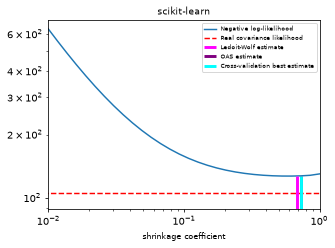

In [3]:
def plot(ax, title, negative_logliks, loglik_real, lw_s, lw_ll, oa_s, oa_ll, cv_s, cv_ll):
    ax.set_title(title, fontsize=9)
    ax.loglog(shrinkages, negative_logliks, label="Negative log-likelihood")
    ax.plot(ax.get_xlim(), 2 * [loglik_real], "--r", label="Real covariance likelihood")
    lik_max, lik_min = np.amax(negative_logliks), np.amin(negative_logliks)
    ymin = lik_min - 6.0 * np.log((ax.get_ylim()[1] - ax.get_ylim()[0]))
    ymax = lik_max + 10.0 * np.log(lik_max - lik_min)
    ax.vlines(lw_s, ymin, -lw_ll, color="magenta", linewidth=3, label="Ledoit-Wolf estimate")
    ax.vlines(oa_s, ymin, -oa_ll, color="purple", linewidth=3, label="OAS estimate")
    ax.vlines(cv_s, ymin, -cv_ll, color="cyan", linewidth=3, label="Cross-validation best estimate")
    ax.set_ylim(ymin, ymax); ax.set_xlim(shrinkages[0], shrinkages[-1]); ax.legend(fontsize=6)
    ax.set_xlabel("shrinkage coefficient", fontsize=8)

sk_cv_s, sk_cv_ll = cv.best_estimator_.shrinkage, cv.best_estimator_.score(X_test)
fig, ax = plt.subplots(figsize=(5, 3.5), dpi=70)
plot(ax, "scikit-learn", negative_logliks, loglik_real, lw.shrinkage_, loglik_lw, oa.shrinkage_, loglik_oa, sk_cv_s, sk_cv_ll)
plt.show()

Learned attributes, functional forms and lifecycle checks beyond the gallery, plus the data shared with Moxie.

In [4]:
from sklearn.base import clone
from sklearn.covariance import ledoit_wolf, ledoit_wolf_shrinkage, oas, shrunk_covariance
extra = {}
extra["lw_cov"], extra["lw_prec"], extra["lw_loc"] = lw.covariance_, lw.precision_, lw.location_
extra["oa_cov"], extra["oa_prec"] = oa.covariance_, oa.precision_
c, s = ledoit_wolf(X_train); extra["f_lw_cov"], extra["f_lw_s"] = c, s
extra["f_lw_shrinkage"] = ledoit_wolf_shrinkage(X_train, block_size=7)
c, s = oas(X_train); extra["f_oas_cov"], extra["f_oas_s"] = c, s
extra["f_shrunk"] = shrunk_covariance(emp_cov, shrinkage=0.3)
extra["error_norms"] = np.array([lw.error_norm(real_cov), lw.error_norm(real_cov, norm="spectral"),
                                 lw.error_norm(real_cov, scaling=False), lw.error_norm(real_cov, squared=False)])
extra["lw_mahal"] = lw.mahalanobis(X_test)
nostore = ShrunkCovariance(store_precision=False, shrinkage=0.25).fit(X_train)
print("store_precision=False -> precision_ is", nostore.precision_)
extra["nostore_prec"] = nostore.get_precision()
sc = ShrunkCovariance(shrinkage=0.1).fit(X_train)
sc.set_params(shrinkage=0.6, assume_centered=True)
sc.fit(X_train)
extra["set_params_cov"], extra["set_params_score"] = sc.covariance_, sc.score(X_test)
extra["cv_mean"] = cv.cv_results_["mean_test_score"]
extra["cv_best"] = np.array([sk_cv_s, cv.best_score_, sk_cv_ll])
X_train32 = X_train.astype(np.float32)
lw32, oa32 = LedoitWolf().fit(X_train32), OAS().fit(X_train32)
extra["lw32_cov"], extra["lw32_s"] = lw32.covariance_, lw32.shrinkage_
extra["oa32_cov"], extra["oa32_s"] = oa32.covariance_, oa32.shrinkage_
print("Float32 covariance_ dtypes:", lw32.covariance_.dtype, oa32.covariance_.dtype)
print("clone of fitted LedoitWolf is unfitted:", not hasattr(clone(lw), "covariance_"))
cond = np.linalg.cond(lw.covariance_)
print("condition numbers: LW %.3g  OAS %.3g  shrinkage=0.01 %.3g"
      % (cond, np.linalg.cond(oa.covariance_), np.linalg.cond(ShrunkCovariance(shrinkage=0.01).fit(X_train).covariance_)))
nb.share(X_train=X_train, X_test=X_test, shrinkages=shrinkages, real_cov=real_cov,
         real_prec=linalg.inv(real_cov), X_train32=X_train32)

store_precision=False -> precision_ is None
Float32 covariance_ dtypes: float32 float32
clone of fitted LedoitWolf is unfitted: True
condition numbers: LW 3.93  OAS 3.32  shrinkage=0.01 639


## 2. Moxie (native Mojo)

The same scenario through `moxie.covariance`; learning and scoring happen in Mojo.

In [5]:
%%mojo shrinkage
from numojo import NDArray, Shape
from moxie.base import clone
from moxie.covariance import (ShrunkCovariance, LedoitWolf, OAS, empirical_covariance, log_likelihood,
                              ledoit_wolf, ledoit_wolf_shrinkage, oas, shrunk_covariance)
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X_train = load("X_train")
    var X_test = load("X_test")
    var shrinkages = load("shrinkages")
    var real_cov = load("real_cov")
    var real_prec = load("real_prec")

    var negative_logliks = List[Float64]()
    for i in range(shrinkages.size):
        var model = ShrunkCovariance(shrinkage=Float64(shrinkages.unsafe_get(i)))
        negative_logliks.append(-model.fit(X_train).score(X_test))
    save_floats("negative_logliks", negative_logliks)
    var emp_cov = empirical_covariance(X_train)
    save("emp_cov", emp_cov)
    save_floats("loglik_real", [-log_likelihood(emp_cov, real_prec)])

    var lw = LedoitWolf()
    var loglik_lw = lw.fit(X_train).score(X_test)
    var oa = OAS()
    var loglik_oa = oa.fit(X_train).score(X_test)
    save_floats("scalars", [lw.shrinkage_(), loglik_lw, oa.shrinkage_(), loglik_oa])
    save("lw_cov", lw.covariance_())
    save("lw_prec", lw.precision_().value())
    save("lw_loc", lw.location_())
    save("oa_cov", oa.covariance_())
    save("oa_prec", oa.precision_().value())
    print("LedoitWolf shrinkage_", lw.shrinkage_(), " OAS shrinkage_", oa.shrinkage_())

    var f_lw = ledoit_wolf(X_train)
    save("f_lw_cov", f_lw[0])
    var f_oas = oas(X_train)
    save("f_oas_cov", f_oas[0])
    save_floats("f_scalars", [f_lw[1], ledoit_wolf_shrinkage(X_train, block_size=7), f_oas[1]])
    save("f_shrunk", shrunk_covariance(emp_cov, shrinkage=0.3))
    save_floats("error_norms", [lw.error_norm(real_cov), lw.error_norm(real_cov, norm="spectral"),
                                lw.error_norm(real_cov, scaling=False), lw.error_norm(real_cov, squared=False)])
    save("lw_mahal", lw.mahalanobis(X_test))

    var nostore = ShrunkCovariance(store_precision=False, shrinkage=0.25)
    _ = nostore.fit(X_train)
    print("store_precision=False -> precision_ is None:", not nostore.precision_())
    save("nostore_prec", nostore.get_precision())

    var sc = ShrunkCovariance(shrinkage=0.1)
    _ = sc.fit(X_train)
    _ = sc.set_params(shrinkage=0.6, assume_centered=True)
    _ = sc.fit(X_train)
    save("set_params_cov", sc.covariance_())
    save_floats("set_params_score", [sc.score(X_test)])

    var X_train32 = load[DType.float32]("X_train32")
    var lw32 = LedoitWolf[DType.float32]()
    _ = lw32.fit(X_train32)
    var oa32 = OAS[DType.float32]()
    _ = oa32.fit(X_train32)
    save("lw32_cov", lw32.covariance_())
    save("oa32_cov", oa32.covariance_())
    save_floats("f32_scalars", [lw32.shrinkage_(), oa32.shrinkage_()])
    print("Float32 covariance_ dtype:", lw32.covariance_().dtype)

    var unfitted = clone(lw)
    var raised = False
    try:
        _ = unfitted.covariance_()
    except e:
        raised = String(e).startswith("NotFittedError")
        print("clone(lw).covariance_() ->", String(e))
    save_ints("clone_unfitted", [1 if raised else 0])

LedoitWolf shrinkage_ 0.6873137537323872  OAS shrinkage_ 0.7350860457721696
store_precision=False -> precision_ is None: True
Float32 covariance_ dtype: float32
clone(lw).covariance_() -> NotFittedError: This LedoitWolf instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.


`GridSearchCV(ShrunkCovariance(), {"shrinkage": shrinkages})` with the default 5-fold `KFold` and the estimator's own `score`.

In [6]:
%%mojo shrinkage_search
from numojo import NDArray, Shape
from moxie.covariance import ShrunkCovariance
from moxie.model_selection import GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer
from moxie.model_selection._split import _rows
from moxie_nb_io import load, save, save_floats

comptime Dense = NDArray[DType.float64]


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct LogLikelihood(SearchScorer):
    # sklearn's default for an estimator without `scoring`: estimator.score(X_test) (Gaussian log-likelihood).
    comptime Estimator = ShrunkCovariance[]
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: ShrunkCovariance[], X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X)


struct ShrinkageSearch(SearchAdapter):
    comptime Scorer = LogLikelihood
    comptime Value = Float64

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: ShrunkCovariance[], X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X)

    def configure(self, mut estimator: ShrunkCovariance[], params: Dict[String, Float64]) raises:
        for key in params.keys():
            if key != "shrinkage":
                raise Error("ValueError: this adapter tunes only shrinkage")
        _ = estimator.set_params(shrinkage=params["shrinkage"])

    def default_scorer(self) raises -> LogLikelihood:
        return LogLikelihood()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(X.shape[0])


def main() raises:
    var X_train = load("X_train")
    var X_test = load("X_test")
    var shrinkages = load("shrinkages")
    var grid = Dict[String, List[Float64]]()
    var values = List[Float64]()
    for i in range(shrinkages.size):
        values.append(Float64(shrinkages.unsafe_get(i)))
    grid["shrinkage"] = values^
    var ignored = NDArray[DType.float64](Shape(X_train.shape[0]))
    for i in range(X_train.shape[0]):
        ignored.unsafe_set(i, 0)
    var search = GridSearchCV[ShrinkageSearch](ShrunkCovariance(), grid, ShrinkageSearch(), cv=kfold(X_train.shape[0]))
    search.fit(X_train, ignored, None, None)
    save("cv_mean", search.cv_results_().mean_test_score)
    var best = search.best_estimator_().shrinkage
    save_floats("cv_best", [best, search.best_score_(), search.best_estimator_().score(X_test)])
    print("CV best shrinkage", best)

CV best shrinkage 0.727895384398315


## 3. Side by side and parity

Every tolerance is justified next to its check.

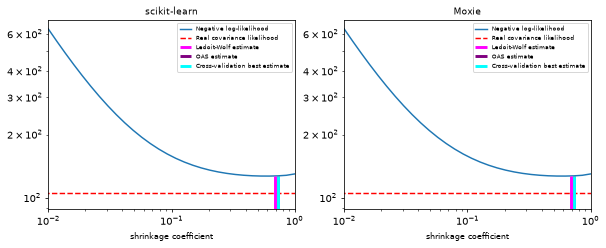

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"ShrunkCovariance score, 30 shrinkages (negative log-likelihood)",PASS,"(30,)","(30,)",1.67e-11,2.63e-14,"rtol=1e-11, atol=0",,"log-det/trace of precisions with condition numbers up to 6.4e2 (shrinkage=0.01, printed above): kappa * p * eps ~ 6e-12 relative bound on the score"
empirical_covariance(X_train),PASS,"(40, 40)","(40, 40)",1.42e-14,1.57e-14,"rtol=0, atol=6.8795e-11",,"Float64 Gram products of 20x40 data: BLAS vs native summation order, a few ulps of the entry scale"
"-log_likelihood(emp_cov, inv(real_cov))",PASS,"(1,)","(1,)",5.67e-12,5.4e-14,"rtol=1e-11, atol=0",,trace of a 40x40 product plus log-det of the shared true precision; summation order only
LedoitWolf shrinkage_,PASS,"(1,)","(1,)",6.66e-16,9.69e-16,"rtol=1e-12, atol=0",,ratio of Frobenius moments; summation order
OAS shrinkage_,PASS,"(1,)","(1,)",3.33e-16,4.53e-16,"rtol=1e-12, atol=0",,closed form of trace moments; summation order
LedoitWolf score(X_test),PASS,"(1,)","(1,)",4.26e-14,3.35e-16,"rtol=1e-11, atol=0",,well-conditioned precision (see condition numbers above)
OAS score(X_test),PASS,"(1,)","(1,)",0,0,"rtol=1e-11, atol=0",,well-conditioned precision
lw_cov,PASS,"(40, 40)","(40, 40)",2.84e-14,1.78e-14,"rtol=0, atol=4.54523e-11",,"Float64 Gram products of 20x40 data: BLAS vs native summation order, a few ulps of the entry scale"
oa_cov,PASS,"(40, 40)","(40, 40)",1.24e-14,1.7e-14,"rtol=0, atol=4.38299e-11",,"Float64 Gram products of 20x40 data: BLAS vs native summation order, a few ulps of the entry scale"
f_lw_cov,PASS,"(40, 40)","(40, 40)",2.84e-14,1.78e-14,"rtol=0, atol=4.54523e-11",,"Float64 Gram products of 20x40 data: BLAS vs native summation order, a few ulps of the entry scale"


In [7]:
mx, ms = nb.results["shrinkage"], nb.results["shrinkage_search"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=70)
plot(axes[0], "scikit-learn", negative_logliks, loglik_real, lw.shrinkage_, loglik_lw, oa.shrinkage_, loglik_oa, sk_cv_s, sk_cv_ll)
sc_ = mx["scalars"]
plot(axes[1], "Moxie", mx["negative_logliks"], float(mx["loglik_real"][0]), sc_[0], sc_[1], sc_[2], sc_[3],
     ms["cv_best"][0], ms["cv_best"][2])
plt.show()
moxie_nb.side_by_side(
    sklearn=dict(lw_shrinkage=lw.shrinkage_, oas_shrinkage=oa.shrinkage_, cv_best=sk_cv_s, loglik_lw=loglik_lw, loglik_oa=loglik_oa),
    moxie=dict(lw_shrinkage=sc_[0], oas_shrinkage=sc_[2], cv_best=ms["cv_best"][0], loglik_lw=sc_[1], loglik_oa=sc_[3]))

EPS = np.finfo(np.float64).eps
# Same closed-form Float64 algorithms; differences come from matrix-product/BLAS summation order (a few ulps per
# entry of the 40x40 covariance) and are amplified by inverses/log-determinants by the condition number.
COV = "Float64 Gram products of 20x40 data: BLAS vs native summation order, a few ulps of the entry scale"
nb.compare("ShrunkCovariance score, 30 shrinkages (negative log-likelihood)", negative_logliks, mx["negative_logliks"],
           rtol=1e-11, atol=0, reason="log-det/trace of precisions with condition numbers up to 6.4e2 (shrinkage=0.01, printed above): "
           "kappa * p * eps ~ 6e-12 relative bound on the score")
nb.compare("empirical_covariance(X_train)", emp_cov, mx["emp_cov"], rtol=0, atol=1e-12 * np.abs(emp_cov).max(), reason=COV)
nb.compare("-log_likelihood(emp_cov, inv(real_cov))", np.array([loglik_real]), mx["loglik_real"], rtol=1e-11, atol=0,
           reason="trace of a 40x40 product plus log-det of the shared true precision; summation order only")
nb.compare("LedoitWolf shrinkage_", np.array([lw.shrinkage_]), sc_[[0]], rtol=1e-12, atol=0, reason="ratio of Frobenius moments; summation order")
nb.compare("OAS shrinkage_", np.array([oa.shrinkage_]), sc_[[2]], rtol=1e-12, atol=0, reason="closed form of trace moments; summation order")
nb.compare("LedoitWolf score(X_test)", np.array([loglik_lw]), sc_[[1]], rtol=1e-11, atol=0, reason="well-conditioned precision (see condition numbers above)")
nb.compare("OAS score(X_test)", np.array([loglik_oa]), sc_[[3]], rtol=1e-11, atol=0, reason="well-conditioned precision")
for k in ("lw_cov", "oa_cov", "f_lw_cov", "f_oas_cov", "f_shrunk", "set_params_cov"):
    ref = extra[k]
    nb.compare(k, ref, mx[k], rtol=0, atol=1e-12 * np.abs(ref).max(), reason=COV)
for k in ("lw_prec", "oa_prec", "nostore_prec"):
    ref = extra[k]
    nb.compare(k, ref, mx[k], rtol=0, atol=1e-10 * np.abs(ref).max(), reason="pinvh of a covariance with condition number <= 6.4e2: "
               "kappa * covariance error")
nb.compare("location_", extra["lw_loc"], mx["lw_loc"], rtol=0, atol=1e-13 * np.abs(extra["lw_loc"]).max(), reason="column means; summation order")
nb.compare("ledoit_wolf / ledoit_wolf_shrinkage(block_size=7) / oas coefficients",
           np.array([extra["f_lw_s"], extra["f_lw_shrinkage"], extra["f_oas_s"]]), mx["f_scalars"], rtol=1e-12, atol=0,
           reason="blocked moment sums: summation order only")
nb.compare("error_norm (frobenius, spectral, unscaled, not squared)", extra["error_norms"], mx["error_norms"], rtol=1e-11, atol=0,
           reason="norm of a covariance difference; spectral uses an SVD (LAPACK vs native) agreeing to ~1e-12 relative")
nb.compare("mahalanobis(X_test)", extra["lw_mahal"], mx["lw_mahal"], rtol=1e-10, atol=0,
           reason="direct quadratic form vs sklearn's cdist(...)**2 (documented in algorithms/empirical/docs/api.md)")
nb.compare("set_params(shrinkage=0.6, assume_centered=True) + refit: score", np.array([extra["set_params_score"]]), mx["set_params_score"],
           rtol=1e-11, atol=0, reason="well-conditioned shrunk covariance")
nb.compare("clone(fitted LedoitWolf) is unfitted (NotFittedError)", np.array([1]), mx["clone_unfitted"], exact=True)
F32 = ("Float32 Gram products of data with entries ~10: float32 rounding (eps 6e-8) accumulated over 20 samples, "
       "BLAS sgemm vs native order; 1e-5 of the matrix scale")
for k in ("lw32_cov", "oa32_cov"):
    ref = extra[k]
    nb.compare(k + " (Float32)", ref, mx[k], rtol=0, atol=1e-5 * np.abs(ref).max(), reason=F32)
nb.compare("Float32 LedoitWolf/OAS shrinkage_", np.array([extra["lw32_s"], extra["oa32_s"]]), mx["f32_scalars"], rtol=1e-5, atol=0, reason=F32)
nb.compare("Float32 covariance_ dtype", np.array([str(extra["lw32_cov"].dtype)]), np.array([str(mx["lw32_cov"].dtype)]), exact=True)
nb.compare("GridSearchCV mean_test_score (30 shrinkages)", extra["cv_mean"], ms["cv_mean"].ravel(), rtol=1e-11, atol=0,
           reason="held-out Gaussian log-likelihoods of 16-sample fits; conditioning as for the score curve")
nb.compare("GridSearchCV best (shrinkage, best_score_, best_estimator_.score(X_test))", extra["cv_best"], ms["cv_best"],
           rtol=1e-11, atol=0, reason="as above; the selected grid value is identical")
nb.note("GridSearchCV adapter", "ADAPTED", "Moxie search adapters are supervised-shaped; an ignored all-zero target is passed "
        "and the scorer calls ShrunkCovariance.score (sklearn's default for scoring=None)")
nb.note("precision_ with store_precision=False", "ADAPTED", "Optional accessor returns None, like sklearn's None attribute")
nb.report()
nb.assert_parity()